<a href="https://colab.research.google.com/github/TianaT6/MSSP607/blob/main/Modules/Week_9/Image_Downloader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Downloader



## 1. Install the required package

In [13]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("requests") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "requests>=2.32,<3"])
print("requests is ready.")

requests is ready.


## 2. Define the program

The program sends the category as a tag, reads the returned image URLs, and saves each image in binary mode. It reports failed downloads and continues with the other images. The manifest records each source and result.

In [14]:
"""Download every image returned by Flickr's public tag feed.

Install: python -m pip install requests
Run:     python image_downloader.py landscape
Scope: the current feed batch (usually 20 images), not all of Flickr.
"""

import json
import re
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlsplit

import requests


def download_images(category, output_root="images"):
    """Search Flickr by tag and save all images in the returned feed."""
    category = category.strip()
    if not category:
        raise ValueError("Enter a category, such as landscape or cats.")

    folder_name = re.sub(r"[^\w-]+", "_", category).strip("_") or "photos"
    folder = Path(output_root) / folder_name
    records = []

    with requests.Session() as session:
        session.headers["User-Agent"] = "ImageDownloader/1.0 (Python learning project)"
        response = session.get(
            "https://www.flickr.com/services/feeds/photos_public.gne",
            params={"tags": category, "tagmode": "all", "format": "json",
                    "nojsoncallback": 1},
            timeout=30,
        )
        response.raise_for_status()
        feed = response.json()
        photos = feed["items"]
        folder.mkdir(parents=True, exist_ok=True)
        (folder / "feed.json").write_text(
            json.dumps(feed, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        print(f"Category: {category}")
        print(f"Images returned by Flickr: {len(photos)}")

        for number, photo in enumerate(photos, start=1):
            image_url = photo["media"]["m"]
            filename = Path(urlsplit(image_url).path).name
            record = {"title": photo["title"], "author": photo["author"],
                      "photo_page": photo["link"], "image_url": image_url,
                      "filename": filename, "status": "failed"}
            try:
                image = session.get(image_url, timeout=30)
                image.raise_for_status()
                if not image.headers.get("Content-Type", "").startswith("image/"):
                    raise ValueError("The response is not an image.")
                if not image.content:
                    raise ValueError("The image is empty.")
                with open(folder / filename, "wb") as image_file:
                    image_file.write(image.content)
                record["status"] = "saved"
                print(f"[{number}/{len(photos)}] Saved {filename}")
            except (requests.RequestException, OSError, ValueError) as error:
                record["error"] = str(error)
                print(f"[{number}/{len(photos)}] Failed: {error}")
            records.append(record)
            time.sleep(0.2)

    saved = sum(record["status"] == "saved" for record in records)
    result = {"category": category, "checked_at_utc": datetime.now(timezone.utc).isoformat(),
              "search_url": response.url, "returned": len(photos), "saved": saved,
              "failed": len(photos) - saved, "folder": str(folder), "images": records}
    (folder / "manifest.json").write_text(
        json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(f"Finished: {saved} saved, {result['failed']} failed.")
    if not photos:
        print("No matching photos were returned. Try another category.")
    print(f"Output folder: {folder}")
    return result

## 3. Choose a category and download

Examples: `landscape`, `cats`, or `flowers`. Use comma-separated tags, such as `mountain,snow`, to require both tags.

In [9]:
category = "landscape"
result = download_images(category)

Category: landscape
Images returned by Flickr: 20
[1/20] Saved 55631812972_7a21aac020_m.jpg
[2/20] Saved 55632912233_74b0fd4130_m.jpg
[3/20] Saved 55632979299_a9bef8d2af_m.jpg
[4/20] Saved 55633200720_5745b34d9e_m.jpg
[5/20] Saved 55633153915_a285a0d146_m.jpg
[6/20] Saved 55632864548_7430bab536_m.jpg
[7/20] Saved 55631734502_df5e221564_m.jpg
[8/20] Saved 55632933584_4b7ea59950_m.jpg
[9/20] Saved 55632865273_8bb43515db_m.jpg
[10/20] Saved 55632937264_f7b8f4458a_m.jpg
[11/20] Saved 55631738062_f7242a6c63_m.jpg
[12/20] Saved 55631732257_e4c61c24d9_m.jpg
[13/20] Saved 55632811040_cbcef59252_m.jpg
[14/20] Saved 55632914864_7c6efb77d8_m.jpg
[15/20] Saved 55631674117_0784b25689_m.jpg
[16/20] Saved 55633105450_08cf5e62d9_m.jpg
[17/20] Saved 55631633697_9b10db8bde_m.jpg
[18/20] Saved 55632860599_bc3381de45_m.jpg
[19/20] Saved 55632843559_b1bd523c8e_m.jpg
[20/20] Saved 55633062745_018385df8c_m.jpg
Finished: 20 saved, 0 failed.
Output folder: images/landscape


## 4. Check the saved files

Check the files from this run, rather than counting files from earlier runs.

In [10]:
folder = Path(result["folder"])
saved_paths = [folder / item["filename"] for item in result["images"]
               if item["status"] == "saved"]
assert len(saved_paths) == result["saved"]
assert all(path.is_file() and path.stat().st_size > 0 for path in saved_paths)
print("Images returned:", result["returned"])
print("Files saved:", result["saved"])
print("Downloads failed:", result["failed"])
print("Saved files are present and nonempty.")
if result["failed"]:
    print("Some images failed. See manifest.json for details.")

Images returned: 20
Files saved: 20
Downloads failed: 0
Saved files are present and nonempty.


## 5. Preview three downloaded images

55631812972_7a21aac020_m.jpg


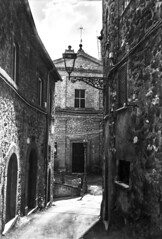

55632912233_74b0fd4130_m.jpg


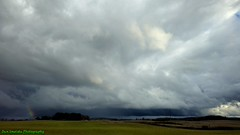

55632979299_a9bef8d2af_m.jpg


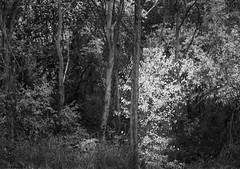

In [11]:
from IPython.display import Image, display

for path in saved_paths[:3]:
    print(path.name)
    display(Image(filename=str(path)))

## 6. Create a ZIP of this run

In Colab, open the Files panel and download `downloaded_images.zip`. The ZIP contains the saved images, their sources, and the feed response.

In [12]:
from zipfile import ZipFile, ZIP_DEFLATED

archive_path = Path("downloaded_images.zip")
with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for path in saved_paths + [folder / "feed.json", folder / "manifest.json"]:
        archive.write(path, arcname=f"{folder.name}/{path.name}")
print("Created:", archive_path)
print("Image files in ZIP:", len(saved_paths))

Created: downloaded_images.zip
Image files in ZIP: 20


## Reading notes and sources

- `requests.get()` retrieves online content.
- `raise_for_status()` checks for HTTP errors.
- `response.json()` converts a JSON response into Python data.
- A loop visits every returned image, and `wb` saves its bytes.

[Sweigart, Chapter 13: Web Scraping](https://automatetheboringstuff.com/3e/chapter13.html), Image Site Downloader practice program.

[Flickr public feed documentation](https://www.flickr.com/services/feeds/docs/photos_public/).

**Limit:** all images means all images in the returned feed batch. The feed has no pagination, so this program does not download the full site-wide category archive. The saved files are feed-sized images, not original-resolution files.